In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [6]:
data = pd.read_csv("Mall_Customers.csv")
data = data.drop("CustomerID", axis=1)
data = data.ffill()
data = pd.get_dummies(data, columns=['Genre'], drop_first=True)

In [7]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
normalized_data = normalize(scaled_data)

In [8]:
pca = PCA(n_components=2)
principal = pca.fit_transform(normalized_data)
X = pd.DataFrame(principal, columns=['P1', 'P2'])

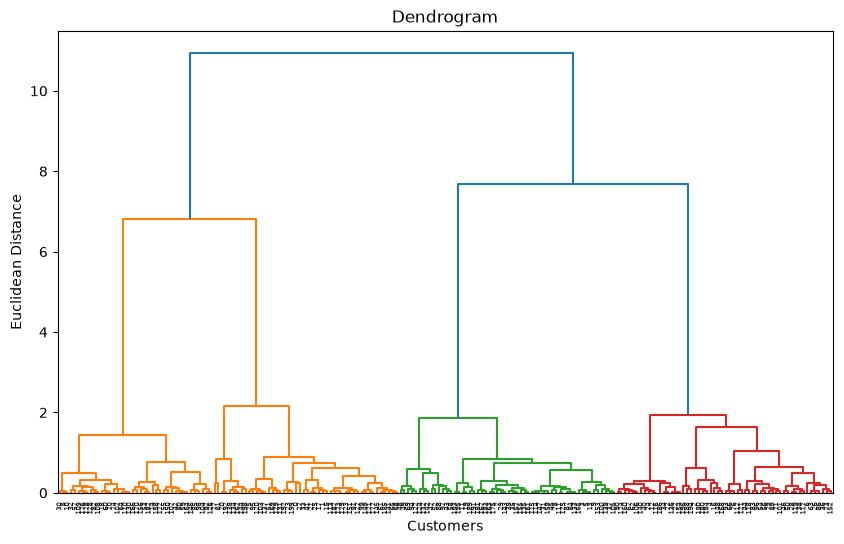

In [9]:
plt.figure(figsize=(10, 6))
linked = linkage(X, method='ward')
dendrogram(linked)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

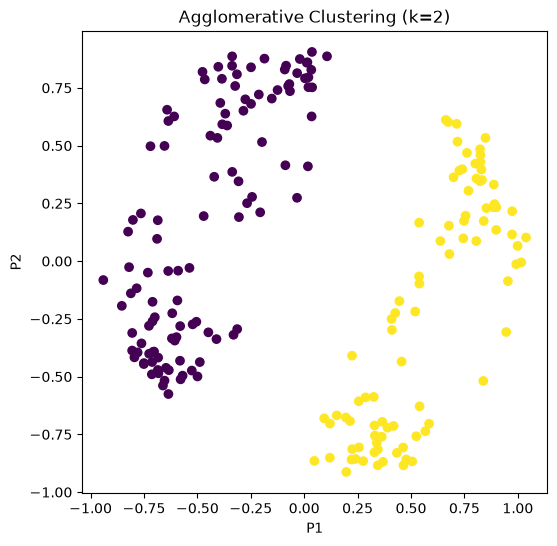

Silhouette Score for k=2: 0.4780


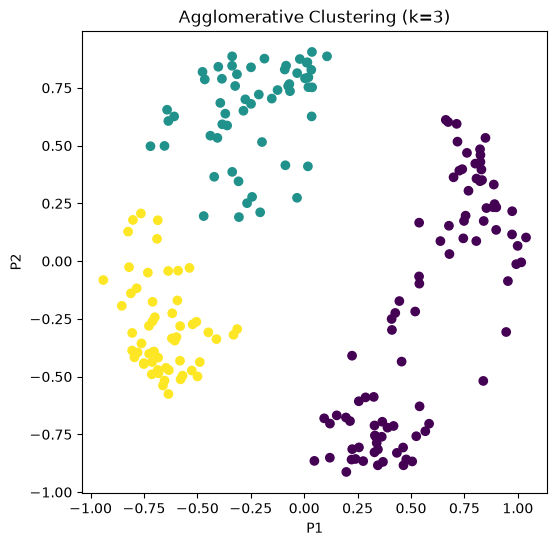

Silhouette Score for k=3: 0.5419


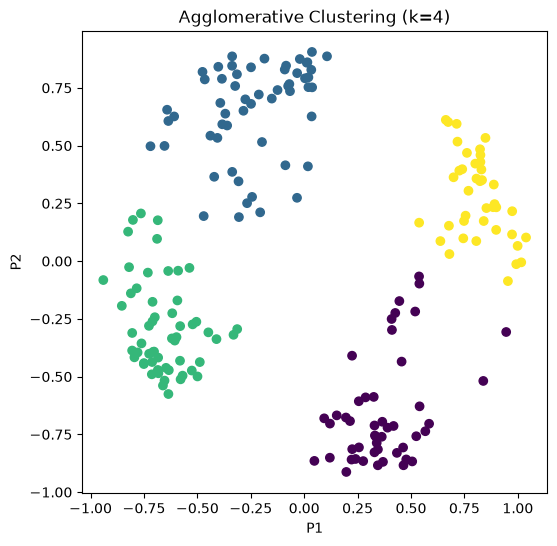

Silhouette Score for k=4: 0.6477


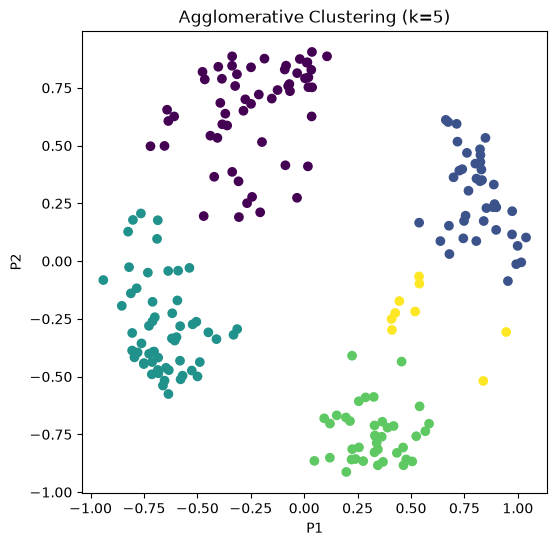

Silhouette Score for k=5: 0.6079


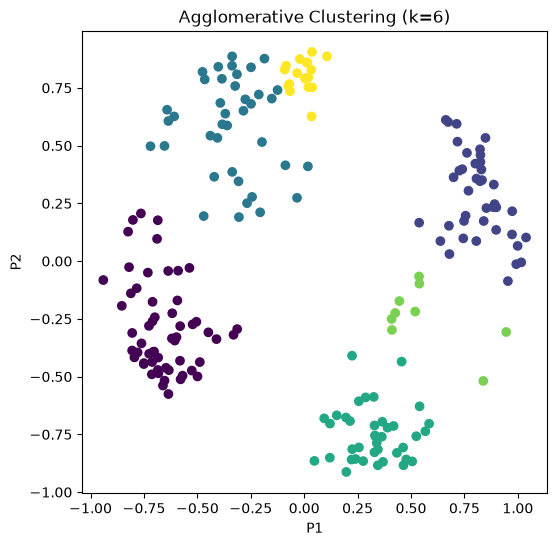

Silhouette Score for k=6: 0.5333


In [10]:
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []
for k in k_values:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

    plt.figure(figsize=(6, 6))
    plt.scatter(
        X['P1'],
        X['P2'],
        c=labels
    )
    plt.title(f"Agglomerative Clustering (k={k})")
    plt.xlabel("P1")
    plt.ylabel("P2")
    plt.show()
    print(f"Silhouette Score for k={k}: {score:.4f}")

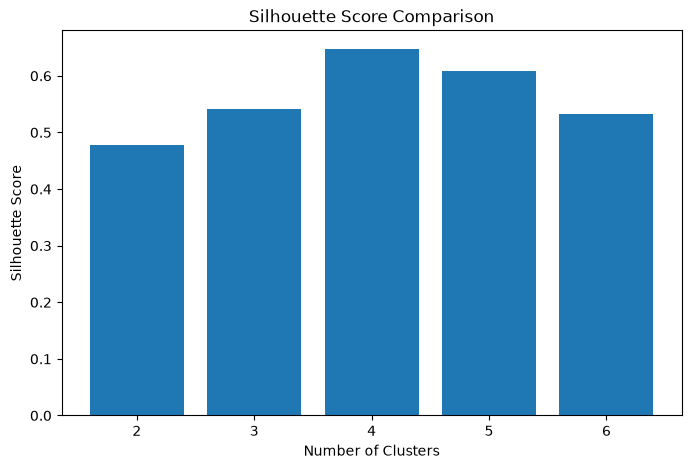

In [11]:
plt.figure(figsize=(8, 5))
plt.bar(k_values, silhouette_scores)
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()

In [12]:
best_k = k_values[np.argmax(silhouette_scores)]
print("\nOptimal Number of Clusters =", best_k)


Optimal Number of Clusters = 4
